In [142]:
!pip install -q opencv-python-headless matplotlib numpy

import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import io

from google.colab import files


Saving pexels-photo-34159490.avif to pexels-photo-34159490 (6).avif


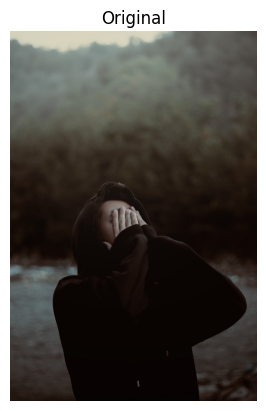

In [143]:
uploaded = files.upload()
filename = list(uploaded.keys())[0]

pil_img = Image.open(io.BytesIO(uploaded[filename])).convert("RGB")
img = cv2.cvtColor(np.array(pil_img), cv2.COLOR_RGB2BGR)

plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original")
plt.axis("off")
plt.show()


In [144]:
def power_law_transform(img, gamma, c=1.0):
    r = img.astype(np.float32) / 255.0
    s = c * np.power(r, gamma)
    s = np.clip(s * 255.0, 0, 255)
    return s.astype(np.uint8)


In [145]:
def histogram_equalization(img):
    ycrcb = cv2.cvtColor(img, cv2.COLOR_BGR2YCrCb)
    y, cr, cb = cv2.split(ycrcb)
    y_eq = cv2.equalizeHist(y)
    merged = cv2.merge((y_eq, cr, cb))
    return cv2.cvtColor(merged, cv2.COLOR_YCrCb2BGR)


In [146]:
def laplacian_sharpen(img, c=1.0):
    laplacian_kernel = np.array([[0,  1, 0],
                                  [1, -4, 1],
                                  [0,  1, 0]], dtype=np.float32)

    img_float = img.astype(np.float32)
    lap = cv2.filter2D(img_float, cv2.CV_32F, laplacian_kernel)

    sharpened = img_float - c * lap
    return np.clip(sharpened, 0, 255).astype(np.uint8)


brightness=52.0 (dark<90, bright>170)
contrast=47.8 (low<40)
blur_score=7.8 (blurry<100)
Fixed: too dark (denoised, then power-law transform, gamma=0.6)


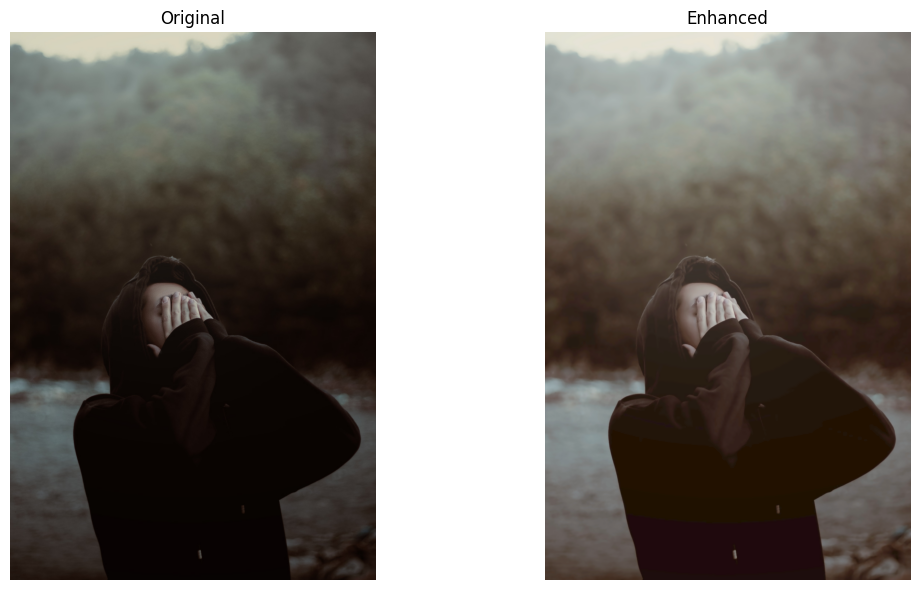

In [147]:
def enhance(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    brightness = gray.mean()
    contrast = gray.std()
    blur_score = cv2.Laplacian(gray, cv2.CV_64F).var()

    print(f"brightness={brightness:.1f} (dark<90, bright>170)")
    print(f"contrast={contrast:.1f} (low<40)")
    print(f"blur_score={blur_score:.1f} (blurry<100)")

    result = img.copy()
    fixed_anything = False

    if brightness < 90:
        result = cv2.fastNlMeansDenoisingColored(result, None, 10, 10, 7, 21)
        result = power_law_transform(result, gamma=0.6)
        print("Fixed: too dark (denoised, then power-law transform, gamma=0.6)")
        fixed_anything = True
    elif brightness > 170:
        result = power_law_transform(result, gamma=1.8)
        print("Fixed: too bright (power-law transform, gamma=1.8)")
        fixed_anything = True

    if contrast < 40:
        result = histogram_equalization(result)
        print("Fixed: low contrast (histogram equalization)")
        fixed_anything = True

    if blur_score < 100 and brightness >= 90:
        result = cv2.GaussianBlur(result, (3, 3), 0)
        result = laplacian_sharpen(result, c=1.0)
        print("Fixed: blurry (smoothed, then Laplacian sharpening)")
        fixed_anything = True

    if not fixed_anything:
        print("No fix applied: image is within normal brightness/contrast/sharpness ranges.")

    return result


enhanced = enhance(img)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
axes[0].set_title("Original")
axes[0].axis("off")
axes[1].imshow(cv2.cvtColor(enhanced, cv2.COLOR_BGR2RGB))
axes[1].set_title("Enhanced")
axes[1].axis("off")
plt.tight_layout()
plt.show()

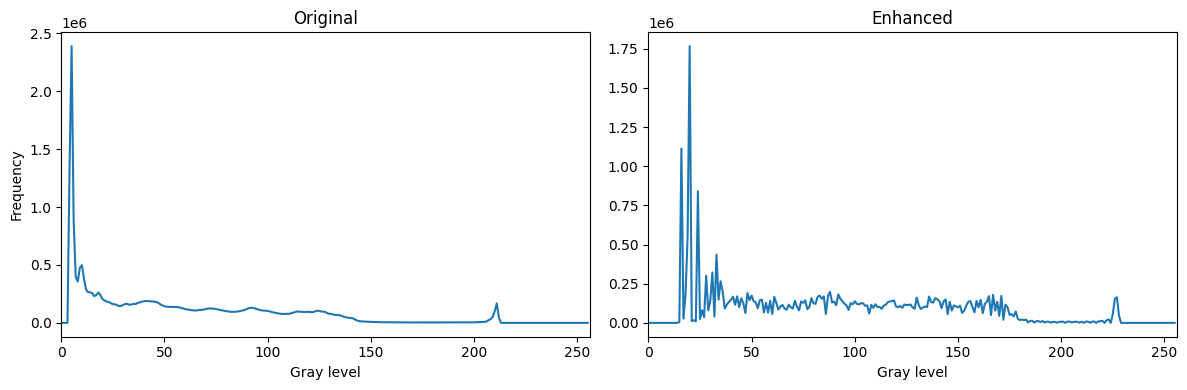

In [148]:
def compare_histograms(img1, img2, label1="Original", label2="Enhanced"):
    gray1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
    gray2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

    hist1 = cv2.calcHist([gray1], [0], None, [256], [0, 256])
    hist2 = cv2.calcHist([gray2], [0], None, [256], [0, 256])

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(hist1)
    axes[0].set_title(label1)
    axes[0].set_xlim([0, 256])
    axes[0].set_xlabel("Gray level")
    axes[0].set_ylabel("Frequency")

    axes[1].plot(hist2)
    axes[1].set_title(label2)
    axes[1].set_xlim([0, 256])
    axes[1].set_xlabel("Gray level")

    plt.tight_layout()
    plt.show()


compare_histograms(img, enhanced)